# 2.1 Aumento de datos con Albumentations

Parte de la Actividad 2.1 dedicada a las transformaciones de **Albumentations** que se agregan al aumento en línea de Ultralytics. El aumento nativo de Ultralytics (mosaico, escala, volteos, HSV…) se analiza en `2.1_hiperparametros.ipynb`.

Con Albumentations instalado, Ultralytics aplica por defecto 4 transformaciones con p = 0.01. La lista que se pasa en el argumento `augmentations` las **reemplaza** (documentación oficial) por un conjunto propio, que se compara en la 2.2.

| Sección | Contenido |
| :--- | :--- |
| 1 | Transformaciones por defecto de Ultralytics frente al conjunto propio |
| 2 | Familias de transformaciones y grupos `OneOf` |
| 3 | Giros de 90° (`RandomRotate90`) |
| 4 | Combinación con el aumento nativo |
| 5 | Configuraciones de aumento que se comparan en la 2.2 |

En las figuras, el borde **verde** marca lo que se mantiene o se prueba, y el **rojo**, lo que se descarta. El notebook no entrena.

In [1]:
import sys
from pathlib import Path

import albumentations as A
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics.cfg import get_cfg

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
import comun_oe2 as E
from comun_oe2 import (FINAL, NOMBRE, stems, SUBTIPOS, OK, MAL, NEUTRO, GRIS, CAJA_OK, CAJA_MAL, CAJA_B,
                       mostrar, cargar, dibujar, recorte, grano, hsv, ejemplos_ultralytics)
C = E.C
SALIDA = RAIZ / 'salida' / '2.1_aumento'
C.estilo()

## 1. Transformaciones por defecto y conjunto propio

Con Albumentations instalado, Ultralytics aplica por defecto `Blur`, `MedianBlur`, `ToGray` y `CLAHE`, cada una con p = 0.01. La lista que se pasa en `augmentations` las **reemplaza** (documentación oficial). Se muestra cada transformación en su parámetro más fuerte (el caso extremo) sobre un grano `Weeveled`, cuyo orificio es el detalle más pequeño que el modelo debe conservar, y sobre un grano `Fungus`, cuyas manchas dependen del color.

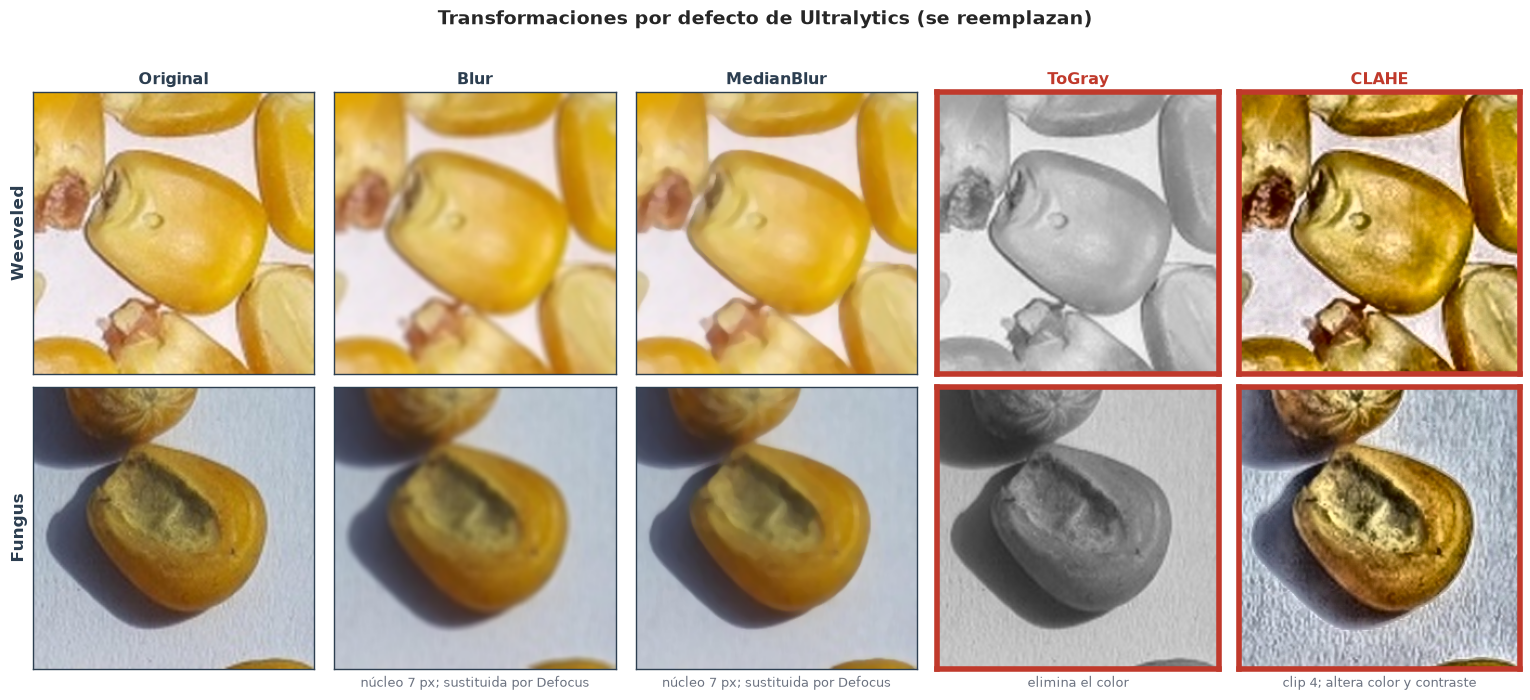

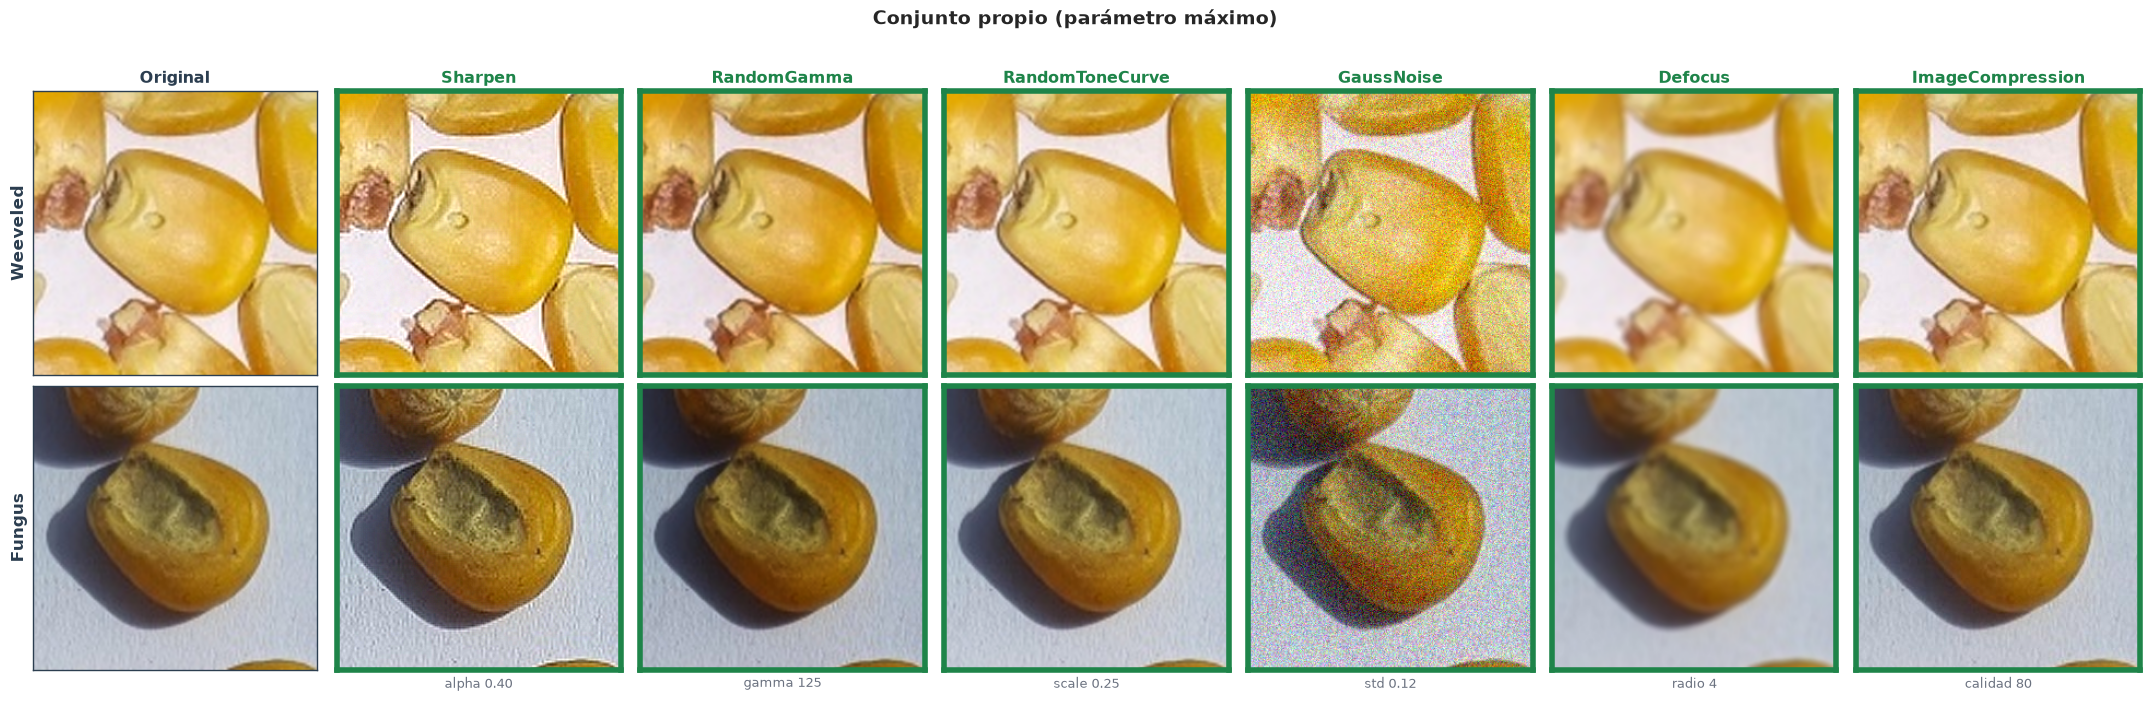

In [2]:
POR_DEFECTO = {'Blur': (A.Blur(blur_limit=(7, 7), p=1), None, 'núcleo 7 px; sustituida por Defocus'),
               'MedianBlur': (A.MedianBlur(blur_limit=(7, 7), p=1), None, 'núcleo 7 px; sustituida por Defocus'),
               'ToGray': (A.ToGray(p=1), 'mal', 'elimina el color'),
               'CLAHE': (A.CLAHE(clip_limit=(4, 4), p=1), 'mal', 'clip 4; altera color y contraste')}
PROPIO = {'Sharpen': (A.Sharpen(alpha=(0.4, 0.4), lightness=(1.05, 1.05), p=1), 'ok', 'alpha 0.40'),
          'RandomGamma': (A.RandomGamma(gamma_limit=(125, 125), p=1), 'ok', 'gamma 125'),
          'RandomToneCurve': (A.RandomToneCurve(scale=0.25, p=1), 'ok', 'scale 0.25'),
          'GaussNoise': (A.GaussNoise(std_range=(0.12, 0.12), p=1), 'ok', 'std 0.12'),
          'Defocus': (A.Defocus(radius=(4, 4), p=1), 'ok', 'radio 4'),
          'ImageCompression': (A.ImageCompression(quality_range=(80, 80), p=1), 'ok', 'calidad 80')}


granos_alb = [grano(9, k=0, lado=260)[0], grano(2, k=1, lado=260)[0]]
for nombre, conjunto, titulo in (('defecto', POR_DEFECTO, 'Transformaciones por defecto de Ultralytics (se reemplazan)'),
                                 ('propio', PROPIO, 'Conjunto propio (parámetro máximo)')):
    fig, axes = plt.subplots(2, len(conjunto) + 1, figsize=(3.1 * (len(conjunto) + 1), 6.9))
    for i, g in enumerate(granos_alb):
        mostrar(axes[i, 0], g, 'Original' if i == 0 else '')
        axes[i, 0].set_ylabel(['Weeveled', 'Fungus'][i], fontsize=12, fontweight='bold', color=NEUTRO)
        for j, (t, (tr, estado, nota)) in enumerate(conjunto.items(), 1):
            mostrar(axes[i, j], A.Compose([tr], seed=0)(image=g)['image'], t if i == 0 else '', nota if i == 1 else None, estado)
    fig.suptitle(titulo, fontsize=14, fontweight='bold', y=1.01)
    C.guardar(SALIDA, f'evidencia_albumentations_{nombre}.png')

**Lectura:**
- **Se descartan dos por evidencia clara:** `ToGray` elimina el color, y `CLAHE` altera el color y el contraste del grano (lo oscurece y le da un tono verdoso que puede parecer un defecto).
- **`Blur` y `MedianBlur`** desenfocan de forma parecida a `Defocus` y en este grano el orificio sigue visible. No se descartan por dañinas, sino por ser de la misma familia que `Defocus` (sección 2).
- **El conjunto propio conserva el color y el orificio.** En su parámetro máximo, `GaussNoise` y `Defocus` son notorios. Por eso en la 2.2 se aplican con probabilidad baja y con rangos que empiezan más suaves.

## 2. Familias de transformaciones y grupos `OneOf`

Varias transformaciones hacen cosas parecidas. Se agrupan por familia para que **no se acumulen dos del mismo tipo en una imagen**: dentro de un `A.OneOf`, Albumentations aplica como máximo una.

| Familia | Transformaciones | En el conjunto de la 2.2 |
| :--- | :--- | :--- |
| **Brillo y contraste** | `hsv_v` (Ultralytics, en cada imagen), `RandomGamma`, `RandomToneCurve` | `OneOf(RandomGamma, RandomToneCurve)`, p = 0.35, sobre `hsv_v` |
| **Nitidez** | `Sharpen` y `Defocus` (opuestas); `Blur` y `MedianBlur` | `OneOf(Sharpen, Defocus)`, p = 0.40. `Blur` y `MedianBlur` no se incluyen |
| **Artefactos de cámara** | `GaussNoise` (ruido del sensor), `ImageCompression` (JPEG) | Independientes: en una cámara real ocurren juntos |
| **Color** | `hsv_h`, `hsv_s` | Solo Ultralytics |

- **Brillo y contraste:** las tres cambian la luminancia, pero de forma distinta (figura siguiente):
  - `hsv_v` multiplica el brillo de forma lineal; al aclarar, satura los tonos más claros.
  - `RandomGamma` curva los tonos medios, como la exposición de una cámara, y mantiene fijos el negro y el blanco.
  - `RandomToneCurve` aplica una curva tonal aleatoria que cambia la relación entre zonas claras y oscuras.

  El `OneOf` evita que una imagen oscurecida por `hsv_v` se oscurezca otra vez con `RandomGamma`, lo que daría un caso más extremo que cualquier foto real.
- **Nitidez:** `Sharpen` y `Defocus` son opuestas; aplicarlas juntas se anula en parte. `Defocus` simula el desenfoque de la lente, un efecto real de la cámara. `Blur` (promedio de píxeles vecinos) y `MedianBlur` (filtro para eliminar ruido) añadirían variantes del mismo efecto sin información nueva, por eso no se incluyen.
- **Probabilidades:** la de cada `OneOf` es la suma de las probabilidades individuales previstas (0.20 + 0.15 y 0.25 + 0.15), así que se conserva la misma frecuencia de cada familia.

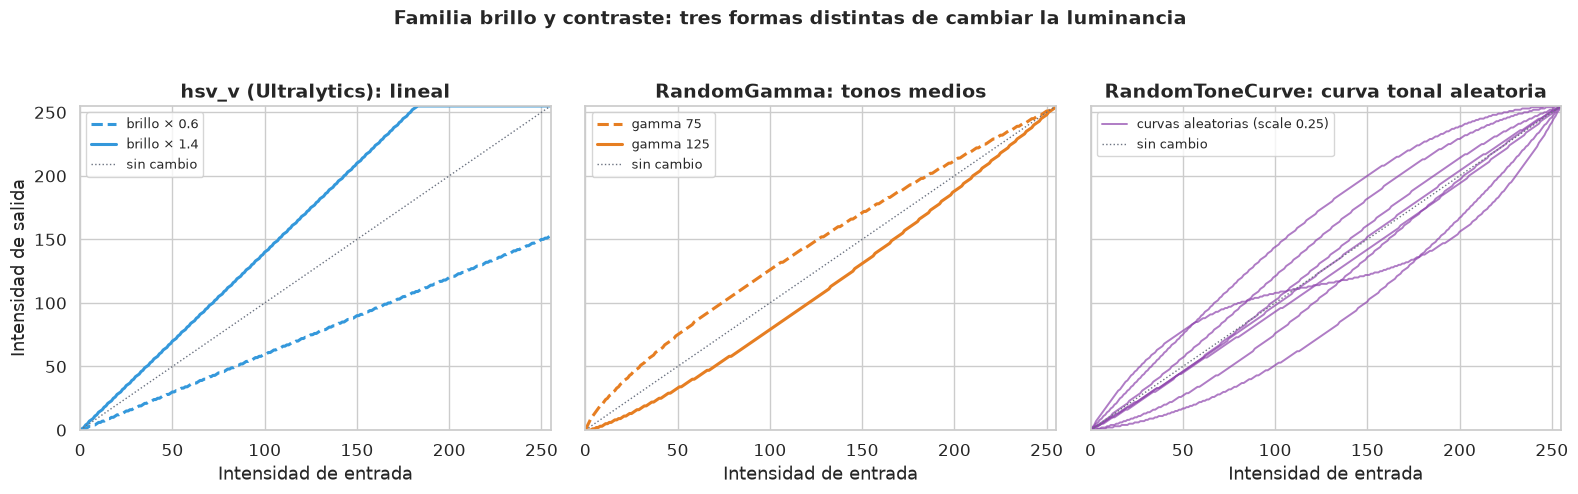

p = 0.35  RandomGamma o RandomToneCurve
p = 0.40  Sharpen o Defocus
p = 0.20  GaussNoise
p = 0.15  ImageCompression


In [3]:
# Curvas de intensidad: cómo transforma cada una un degradado de gris de 0 a 255
rampa = np.repeat(np.tile(np.arange(256, dtype=np.uint8), (4, 1))[..., None], 3, axis=2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
x = np.arange(256)
for v, est in ((0.6, '--'), (1.4, '-')):
    axes[0].plot(x, hsv(rampa, v=v)[0, :, 0], color='#3498DB', ls=est, lw=2.2, label=f'brillo × {v}')
for gm, est in ((75, '--'), (125, '-')):
    axes[1].plot(x, A.Compose([A.RandomGamma(gamma_limit=(gm, gm), p=1)], seed=0)(image=rampa)['image'][0, :, 0], color='#E67E22', ls=est, lw=2.2, label=f'gamma {gm}')
for k in range(8):
    axes[2].plot(x, A.Compose([A.RandomToneCurve(scale=0.25, p=1)], seed=k)(image=rampa)['image'][0, :, 0], color='#8E44AD', lw=1.4, alpha=0.7,
                 label='curvas aleatorias (scale 0.25)' if k == 0 else None)
for ax, t in zip(axes, ('hsv_v (Ultralytics): lineal', 'RandomGamma: tonos medios', 'RandomToneCurve: curva tonal aleatoria')):
    ax.plot(x, x, color=GRIS, lw=1, ls=':', label='sin cambio')
    ax.set_title(t); ax.set_xlabel('Intensidad de entrada'); ax.set_xlim(0, 255); ax.set_ylim(0, 255); ax.legend(fontsize=9)
axes[0].set_ylabel('Intensidad de salida')
fig.suptitle('Familia brillo y contraste: tres formas distintas de cambiar la luminancia', fontsize=14, fontweight='bold', y=1.03)
C.guardar(SALIDA, 'evidencia_curvas_intensidad.png')

# Conjunto que se usará en la 2.2: una transformación por familia, con probabilidad baja y rangos que empiezan suaves
AUMENTO_ALBUMENTATIONS = [
    A.OneOf([A.RandomGamma(gamma_limit=(75, 125)), A.RandomToneCurve(scale=0.25)], p=0.35),                         # brillo y contraste
    A.OneOf([A.Sharpen(alpha=(0.25, 0.40), lightness=(0.95, 1.05)), A.Defocus(radius=(2, 4))], p=0.40),            # nitidez
    A.GaussNoise(std_range=(0.06, 0.12), p=0.20),                                                                   # ruido del sensor
    A.ImageCompression(quality_range=(80, 95), p=0.15),                                                             # compresión JPEG
]
for t in AUMENTO_ALBUMENTATIONS:
    print(f'p = {t.p:.2f}  ' + (' o '.join(type(u).__name__ for u in t.transforms) if hasattr(t, 'transforms') else type(t).__name__))

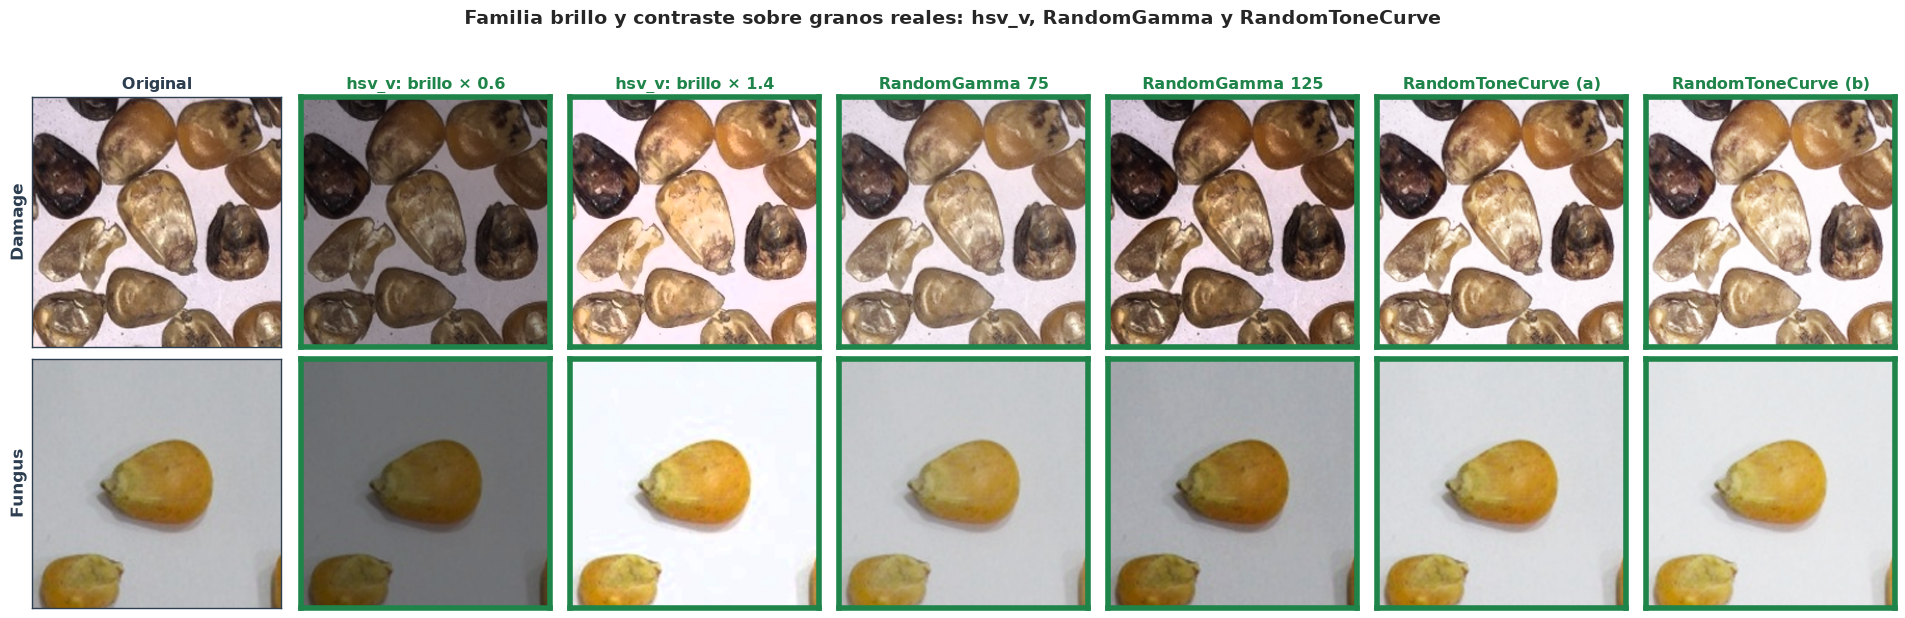

In [4]:
# Las mismas tres familias sobre granos reales (dos lotes distintos)
variantes = [('Original', lambda g: g, None),
             ('hsv_v: brillo × 0.6', lambda g: hsv(g, v=0.6), 'ok'), ('hsv_v: brillo × 1.4', lambda g: hsv(g, v=1.4), 'ok'),
             ('RandomGamma 75', lambda g: A.Compose([A.RandomGamma(gamma_limit=(75, 75), p=1)], seed=0)(image=g)['image'], 'ok'),
             ('RandomGamma 125', lambda g: A.Compose([A.RandomGamma(gamma_limit=(125, 125), p=1)], seed=0)(image=g)['image'], 'ok'),
             ('RandomToneCurve (a)', lambda g: A.Compose([A.RandomToneCurve(scale=0.25, p=1)], seed=1)(image=g)['image'], 'ok'),
             ('RandomToneCurve (b)', lambda g: A.Compose([A.RandomToneCurve(scale=0.25, p=1)], seed=6)(image=g)['image'], 'ok')]
filas = [(1, 3), (2, 0)]   # (subtipo, k): Damage y Fungus de lotes distintos
fig, axes = plt.subplots(len(filas), len(variantes), figsize=(2.75 * len(variantes), 6.2))
for r, (st, k) in enumerate(filas):
    g, _, _ = grano(st, k=k, lado=240, margen=2.2)
    for j, (t, f, est) in enumerate(variantes):
        mostrar(axes[r, j], f(g), t if r == 0 else '', None, est)
    axes[r, 0].set_ylabel(NOMBRE[st], fontsize=12, fontweight='bold', color=NEUTRO)
fig.suptitle('Familia brillo y contraste sobre granos reales: hsv_v, RandomGamma y RandomToneCurve', fontsize=14, fontweight='bold', y=1.02)
C.guardar(SALIDA, 'evidencia_brillo_contraste.png')

## 3. Giros de 90° (`RandomRotate90`)

Ultralytics solo ofrece el giro libre (`degrees`), que agranda las cajas: con 10° el IoU máximo con la caja real del grano ya baja a 0.74 (`2.1_hiperparametros.ipynb`, sección 2.3). El giro exacto de 90° solo se consigue con Albumentations. Mueve las cajas sin agrandarlas y, en una vista cenital, el grano no tiene "arriba". Junto con el volteo vertical de Ultralytics (`flipud`, desactivado por defecto), completa las simetrías de la vista cenital.

In [5]:
AUMENTO_GEOMETRICO = [A.RandomRotate90(p=0.5)]   # se añade a la lista de Albumentations; el volteo vertical va en flipud = 0.5

# Mismas definiciones que usa el entrenamiento de la 2.2 (comun_oe2)
assert repr(AUMENTO_ALBUMENTATIONS) == repr(E.aumento_albumentations()) and repr(AUMENTO_GEOMETRICO) == repr(E.aumento_geometrico())
print('Conjuntos idénticos a los de comun_oe2')

Conjuntos idénticos a los de comun_oe2


## 4. Combinación de aumentos

Ultralytics aplica los aumentos **en cadena sobre cada imagen**, en este orden:
1. mosaico;
2. escala y traslación;
3. Albumentations (el conjunto propio y, en la configuración C, `RandomRotate90`);
4. HSV;
5. volteo vertical;
6. volteo horizontal.

Cada transformación decide por su cuenta, con su probabilidad, si se aplica. Por eso los aumentos geométricos y los fotométricos se combinan en la misma imagen: un mosaico puede salir girado 90°, con la gamma cambiada y con ruido. Los `OneOf` solo impiden que coincidan dos transformaciones de la **misma** familia; entre familias distintas, la combinación es libre y multiplica la variabilidad.

La configuración de aumento C de la 2.2 es esa combinación completa: el aumento por defecto, el conjunto propio de Albumentations, el volteo vertical (`flipud = 0.5`) y `RandomRotate90` (p = 0.5).

Fast image access ✅ (ping: 0.0±0.0 ms, read: 6262.8±384.7 MB/s, size: 296.3 KB)


Scanning /tmp/tmp64azb1zv/labels... 29 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29 3.5Kit/s 0.0s

New cache created: /tmp/tmp64azb1zv/labels.cache


albumentations: OneOf([
  RandomGamma(p=0.5, gamma_limit=(75.0, 125.0)),
  RandomToneCurve(p=0.5, per_channel=False, scale=0.25),
], p=0.35), OneOf([
  Sharpen(p=0.5, alpha=(0.25, 0.4), kernel_size=5, lightness=(0.95, 1.05), method='kernel', sigma=1.0),
  Defocus(p=0.5, alias_blur=(0.1, 0.5), radius=(2, 4)),
], p=0.4), GaussNoise(p=0.2, mean_range=(0.0, 0.0), noise_scale_factor=1.0, per_channel=True, std_range=(0.06, 0.12)), ImageCompression(p=0.15, compression_type='jpeg', quality_range=(80, 95)), RandomRotate90(p=0.5)


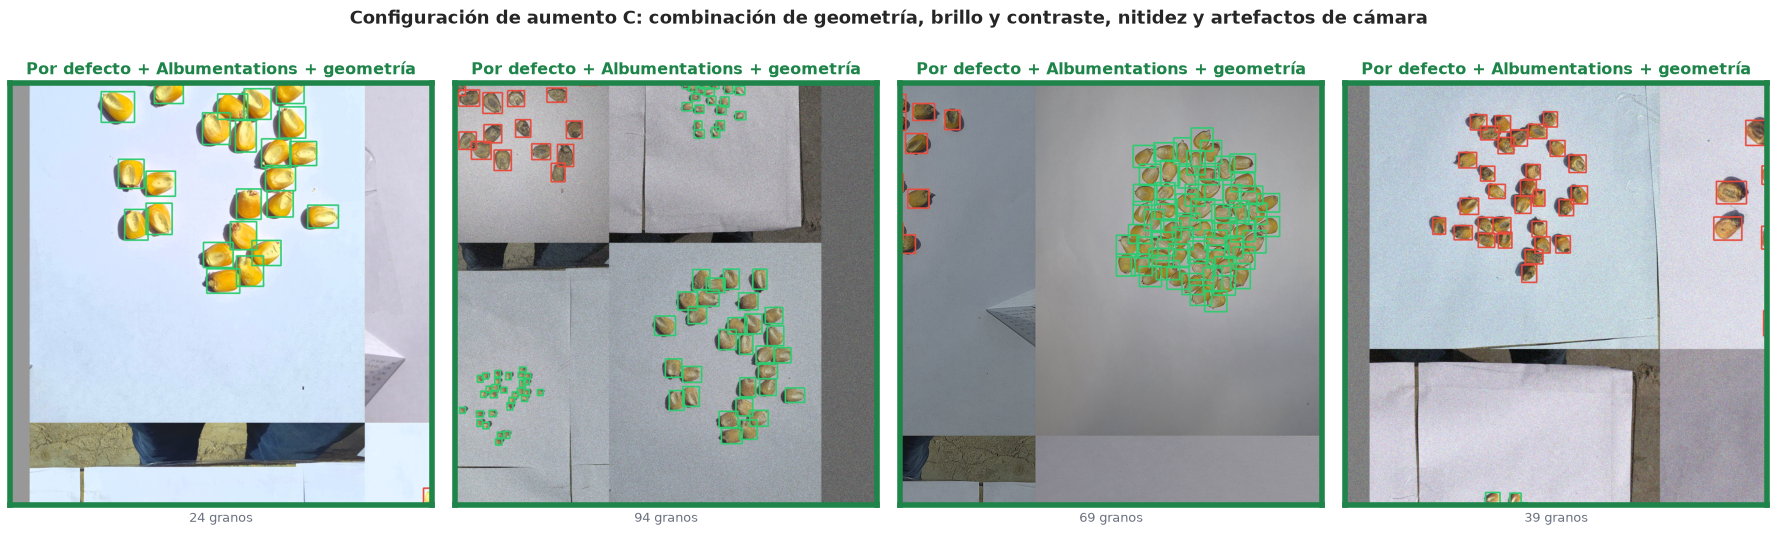

In [6]:
hyp3 = get_cfg(); hyp3.flipud = 0.5; hyp3.augmentations = AUMENTO_ALBUMENTATIONS + AUMENTO_GEOMETRICO
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (img, n) in zip(axes, ejemplos_ultralytics(hyp3, semilla=4)):
    mostrar(ax, img, 'Por defecto + Albumentations + geometría', f'{n} granos', 'ok')
fig.suptitle('Configuración de aumento C: combinación de geometría, brillo y contraste, nitidez y artefactos de cámara', fontsize=13, fontweight='bold', y=1.03)
C.guardar(SALIDA, 'evidencia_aumento_combinado.png')

## 5. Configuraciones de aumento que se comparan en la 2.2

En la 2.2, el aumento es uno de los factores del ajuste: el modelo se entrena con **tres configuraciones de aumento** y se compara cuál da mejor mAP50-95 en validación. Cada configuración añade algo a la anterior:

| Configuración | Qué aumento se aplica | Cómo se configura en Ultralytics |
| :---: | :--- | :--- |
| **A** (referencia) | El aumento por defecto de Ultralytics | Sin cambios |
| **B** | A + conjunto propio de Albumentations | `augmentations = AUMENTO_ALBUMENTATIONS` (reemplaza a las 4 transformaciones por defecto) |
| **C** | B + volteo vertical y giros de 90° | `augmentations = AUMENTO_ALBUMENTATIONS + AUMENTO_GEOMETRICO` y `flipud = 0.5` |

En las tres configuraciones, `bgr`, `degrees`, `shear`, `perspective`, `mixup` y `cutmix` quedan en 0, su valor por defecto.

In [7]:
CONFIGURACIONES_AUMENTO = {
    'A': {},
    'B': {'augmentations': AUMENTO_ALBUMENTATIONS},
    'C': {'augmentations': AUMENTO_ALBUMENTATIONS + AUMENTO_GEOMETRICO, 'flipud': 0.5},
}
def describir(lista):
    if lista is None:
        return 'por defecto: Blur, MedianBlur, ToGray y CLAHE (p = 0.01)'
    return ', '.join(f"una de {' / '.join(type(u).__name__ for u in t.transforms)} (p = {t.p})" if hasattr(t, 'transforms')
                     else f'{type(t).__name__} (p = {t.p})' for t in lista)
pd.set_option('display.max_colwidth', None)
pd.DataFrame([{'configuración': k, 'flipud': v.get('flipud', 0.0), 'Albumentations': describir(v.get('augmentations'))}
              for k, v in CONFIGURACIONES_AUMENTO.items()]).set_index('configuración')

,flipud,Albumentations
configuración,,
A,0.0,"por defecto: Blur, MedianBlur, ToGray y CLAHE (p = 0.01)"
B,0.0,"una de RandomGamma / RandomToneCurve (p = 0.35), una de Sharpen / Defocus (p = 0.4), GaussNoise (p = 0.2), ImageCompression (p = 0.15)"
C,0.5,"una de RandomGamma / RandomToneCurve (p = 0.35), una de Sharpen / Defocus (p = 0.4), GaussNoise (p = 0.2), ImageCompression (p = 0.15), RandomRotate90 (p = 0.5)"


## 6. Resumen

| Decisión | Transformaciones |
| :--- | :--- |
| **Se reemplazan** | Las 4 por defecto de Ultralytics: `ToGray` y `CLAHE` alteran el color; `Blur` y `MedianBlur` son de la misma familia que `Defocus` |
| **Conjunto propio (configuración B)** | Una de `RandomGamma` o `RandomToneCurve`; una de `Sharpen` o `Defocus`; `GaussNoise`; `ImageCompression` |
| **Geometría exacta (configuración C)** | `RandomRotate90`, junto con el volteo vertical de Ultralytics |